In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")
include("../functions.jl")
include("../myfuncs.jl")
include("../integrators.jl")
include("../util_shoji.jl")


simulate_pf_selforg (generic function with 1 method)

Maximum error = 8.33497852532547e-6
L2 error       = 5.893719836129145e-6


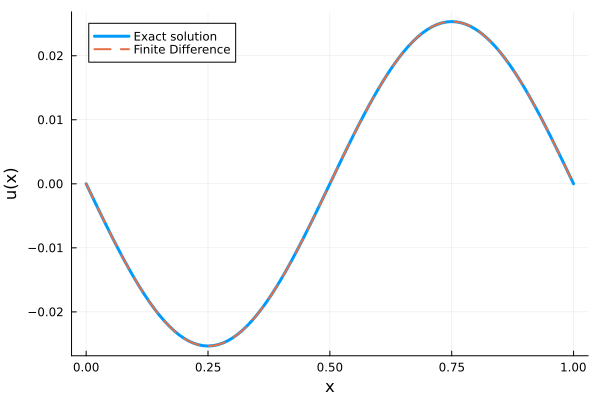

In [5]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------


N = 100                    
h = 1.0 / N
x = collect(0:h:1)

# Interior points
xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# -u'' = f
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = 2.0
    if i > 1
        A[i,i-1] = -1.0
    end
    if i < n
        A[i,i+1] = -1.0
    end
end

A ./= h^2

# Right-hand side
f = -sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact = -(1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact))
l2_error = sqrt(sum((u_num .- u_exact).^2) * h)

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [ ]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------


N = 100                    
h = 1.0 / N
x = collect(0:h:1)

# Interior points
xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# -u'' = f
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = 2.0
    if i > 1
        A[i,i-1] = -1.0
    end
    if i < n
        A[i,i+1] = -1.0
    end
end

A ./= h^2

# Right-hand side
f = -sin.(2π .* xi)

# Solve linear system
u_interior = A \ f

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact = -(1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact))
l2_error = sqrt(sum((u_num .- u_exact).^2) * h)

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

corr = -1.0


In [ ]:
-1 → 本当に位相反転（どこかミス）